# Sensor Modality Decision Contribution

The original section analyzes the standardized saved models using all available windows. The ACC-excluded section retrains each model after removing every ACC-derived feature, then analyzes the remaining modalities on the same windows.

In [1]:
from pathlib import Path
import re
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == '4th try':
    REPO_ROOT = REPO_ROOT.parents[1]
elif not (REPO_ROOT / 'Models').exists() and (Path.cwd().parents[1] / 'Models').exists():
    REPO_ROOT = Path.cwd().parents[1]

DATASET_DIR = REPO_ROOT / 'Data' / 'Preprocessed n STAI-labeled 6s std-norm-ed'
MODEL_DIR = REPO_ROOT / 'Models' / 'stai_6s_standardized'
OUTPUT_DIR = REPO_ROOT / 'Data' / 'Analysis' / 'sensor_modality_decision_contribution'
ACC_EXCLUDED_OUTPUT_DIR = REPO_ROOT / 'Data' / 'Analysis' / 'sensor_modality_decision_contribution_acc_excluded'
ACC_EXCLUDED_MODEL_DIR = REPO_ROOT / 'Models' / 'stai_6s_standardized_acc_excluded'

METADATA_COLUMNS = {'binary_anxiety', 'subject_id', 'condition', 'window_start_seconds', 'window_end_seconds', 'condition_stai_mean', 'baseline_stai_mean'}
MODALITY_PREFIXES = ('net_acc', 'ACC', 'BVP', 'EDA', 'TEMP', 'Temp', 'ECG', 'EMG', 'Resp')
MODEL_FILES = {'Random Forest': 'stai_baseline_relative_random_forest_model.joblib', 'XGBoost': 'stai_baseline_relative_xgboost_model.joblib', 'SVM': 'stai_baseline_relative_svm_model.joblib', 'KNN': 'stai_baseline_relative_knn_model.joblib'}


In [2]:
def load_all_windows(dataset_dir):
    paths = sorted(dataset_dir.glob('S*_stai_60s_shift6s.pkl'))
    if not paths:
        raise FileNotFoundError(f'No STAI 6-second datasets found in {dataset_dir}')
    data = pd.concat([pd.read_pickle(path) for path in paths], ignore_index=True)
    data = data[data['binary_anxiety'].isin([0, 1])].copy()
    feature_columns = [c for c in data.columns if c not in METADATA_COLUMNS]
    data[feature_columns] = data[feature_columns].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan).fillna(0)
    print(f'Analyzing {len(data)} identical windows from {len(paths)} subject files')
    print('Labels:', data['binary_anxiety'].value_counts().sort_index().to_dict())
    return data, feature_columns

def modality_for_feature(feature_name):
    name = re.sub(r'^ACC_sub_', 'ACC_', feature_name)
    for prefix in MODALITY_PREFIXES:
        if name == prefix or name.startswith(f'{prefix}_'):
            return 'ACC' if prefix == 'net_acc' else prefix.upper()
    return 'Other'

def decision_score(model, X):
    if hasattr(model, 'predict_proba'):
        probabilities = model.predict_proba(X)
        classes = list(getattr(model, 'classes_', [0, 1]))
        return probabilities[:, classes.index(1)] if 1 in classes else np.zeros(len(X))
    raw = np.clip(np.asarray(model.decision_function(X)).reshape(-1), -50, 50)
    return 1 / (1 + np.exp(-raw))

WINDOWS, FEATURE_COLUMNS = load_all_windows(DATASET_DIR)
X_ALL = WINDOWS[FEATURE_COLUMNS]
Y_ALL = WINDOWS['binary_anxiety'].astype(int)
FEATURE_MODALITIES = pd.Series([modality_for_feature(c) for c in FEATURE_COLUMNS], index=FEATURE_COLUMNS)


Analyzing 4147 identical windows from 15 subject files
Labels: {0: 3404, 1: 743}


## Original standardized models

Each model below uses all available windows and the standardized model saved by the training notebook.

In [3]:
def analyze_decision_contribution(model_name, filename):
    model = joblib.load(MODEL_DIR / filename)
    expected = getattr(model, 'n_features_in_', None)
    if expected is not None and expected != len(FEATURE_COLUMNS):
        raise ValueError(f'{model_name} expects {expected} features, but dataset provides {len(FEATURE_COLUMNS)}.')
    original_pred = np.asarray(model.predict(X_ALL)).astype(int)
    original_score = decision_score(model, X_ALL)
    medians = X_ALL.median()
    rows = []
    for modality in sorted(FEATURE_MODALITIES.unique()):
        columns = FEATURE_MODALITIES[FEATURE_MODALITIES == modality].index.tolist()
        masked = X_ALL.copy()
        masked[columns] = medians[columns].to_numpy()
        masked_pred = np.asarray(model.predict(masked)).astype(int)
        score_change = np.abs(original_score - decision_score(model, masked))
        pred_change = (original_pred != masked_pred).astype(int)
        for label in [0, 1]:
            selected = original_pred == label
            rows.append({'modality': modality, 'predicted_label': label, 'windows': int(selected.sum()), 'mean_absolute_decision_change': float(score_change[selected].mean()) if selected.any() else 0.0, 'prediction_change_rate': float(pred_change[selected].mean()) if selected.any() else 0.0})
    detail = pd.DataFrame(rows)
    detail['weighted_score_change'] = detail['mean_absolute_decision_change'] * detail['windows']
    detail['weighted_prediction_change'] = detail['prediction_change_rate'] * detail['windows']
    overall = detail.groupby('modality', as_index=False).agg(windows=('windows', 'sum'), weighted_score_change=('weighted_score_change', 'sum'), weighted_prediction_change=('weighted_prediction_change', 'sum'))
    overall['mean_absolute_decision_change'] = overall['weighted_score_change'] / overall['windows']
    overall['prediction_change_rate'] = overall['weighted_prediction_change'] / overall['windows']
    overall = overall.drop(columns=['weighted_score_change', 'weighted_prediction_change']).sort_values('mean_absolute_decision_change', ascending=False, ignore_index=True)
    total = overall['mean_absolute_decision_change'].sum()
    overall['relative_contribution'] = overall['mean_absolute_decision_change'] / total if total else 0.0
    overall['rank'] = np.arange(1, len(overall) + 1)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    stem = Path(filename).stem
    overall.to_csv(OUTPUT_DIR / f'{stem}_overall.csv', index=False)
    detail.to_csv(OUTPUT_DIR / f'{stem}_by_predicted_label.csv', index=False)

    plot_data = overall.sort_values('mean_absolute_decision_change')
    values = plot_data['relative_contribution'] * 100
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(plot_data['modality'], values)
    ax.set_xlabel('Relative contribution to decision change (%)')
    ax.set_ylabel('Sensor modality')
    ax.set_title(f'{model_name}: modality decision contribution')
    for index, value in enumerate(values):
        ax.text(value, index, f' {value:.2f}%', va='center')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'{stem}_overall.png', dpi=160)
    plt.show()
    plt.close(fig)

    print(f'{model_name}: {len(X_ALL)} identical windows; top modality: {overall.iloc[0]["modality"]} ({overall.iloc[0]["relative_contribution"]:.2%})')
    display(overall)
    display(detail)
    return overall, detail


### Random Forest

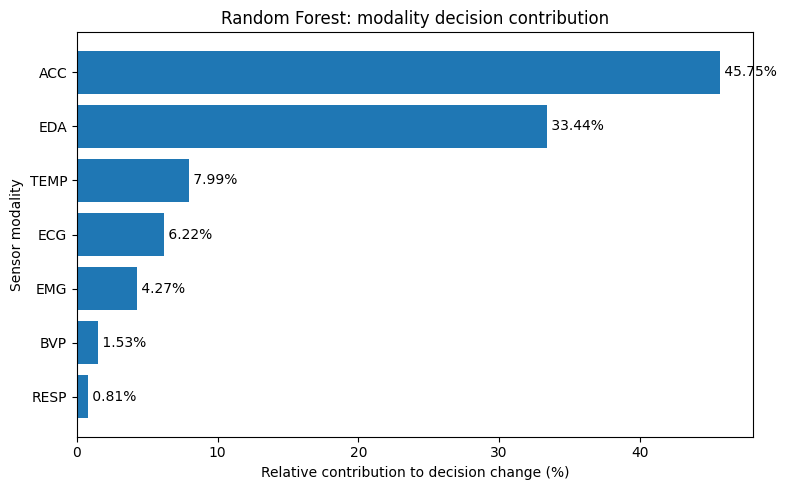

Random Forest: 4147 identical windows; top modality: ACC (45.75%)


,modality,windows,mean_absolute_decision_change,prediction_change_rate,relative_contribution,rank
0,ACC,4147,0.122870,0.126598,0.457467,1
1,EDA,4147,0.089810,0.082469,0.334378,2
2,TEMP,4147,0.021449,0.005787,0.079860,3
3,ECG,4147,0.016694,0.002653,0.062155,4
4,EMG,4147,0.011473,0.000723,0.042717,5
5,BVP,4147,0.004114,0.000482,0.015317,6
6,RESP,4147,0.002177,0.000000,0.008107,7


,modality,predicted_label,windows,mean_absolute_decision_change,prediction_change_rate,weighted_score_change,weighted_prediction_change
0,ACC,0,3522,0.033362,0.000000,117.50,0.0
1,ACC,1,625,0.627264,0.840000,392.04,525.0
2,BVP,0,3522,0.003313,0.000568,11.67,2.0
3,BVP,1,625,0.008624,0.000000,5.39,0.0
4,ECG,0,3522,0.008685,0.002839,30.59,10.0
5,ECG,1,625,0.061824,0.001600,38.64,1.0
6,EDA,0,3522,0.034177,0.000000,120.37,0.0
7,EDA,1,625,0.403312,0.547200,252.07,342.0
8,EMG,0,3522,0.002868,0.000000,10.10,0.0
9,EMG,1,625,0.059968,0.004800,37.48,3.0


In [4]:
random_forest_overall, random_forest_by_label = analyze_decision_contribution('Random Forest', MODEL_FILES['Random Forest'])


### XGBoost

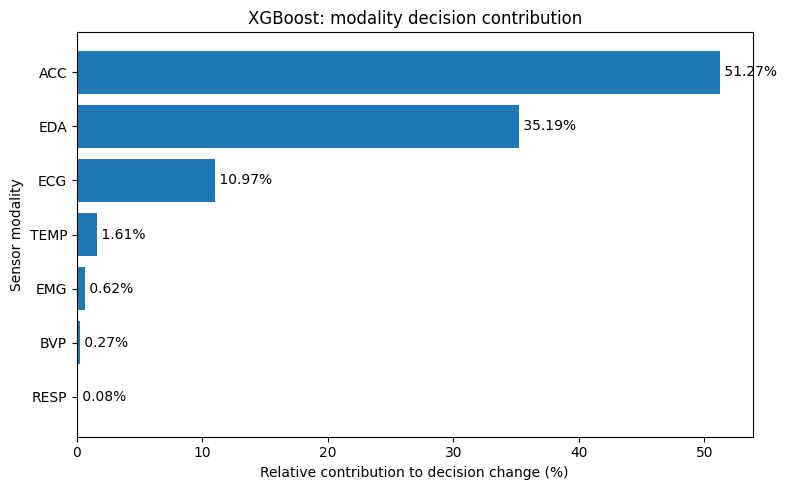

XGBoost: 4147 identical windows; top modality: ACC (51.27%)


,modality,windows,mean_absolute_decision_change,prediction_change_rate,relative_contribution,rank
0,ACC,4147,0.127390,0.129491,0.512667,1
1,EDA,4147,0.087436,0.082710,0.351877,2
2,ECG,4147,0.027267,0.021220,0.109733,3
3,TEMP,4147,0.003990,0.003376,0.016056,4
4,EMG,4147,0.001541,0.000723,0.006200,5
5,BVP,4147,0.000673,0.001929,0.002706,6
6,RESP,4147,0.000189,0.000000,0.000760,7


,modality,predicted_label,windows,mean_absolute_decision_change,prediction_change_rate,weighted_score_change,weighted_prediction_change
0,ACC,0,3504,0.003973,0.000000,13.922501,0.0
1,ACC,1,643,0.799941,0.835148,514.362103,537.0
2,BVP,0,3504,0.000387,0.002283,1.354963,8.0
3,BVP,1,643,0.002230,0.000000,1.433969,0.0
4,ECG,0,3504,0.027537,0.025114,96.488034,88.0
5,ECG,1,643,0.025797,0.000000,16.587433,0.0
6,EDA,0,3504,0.039714,0.036244,139.158565,127.0
7,EDA,1,643,0.347493,0.335925,223.438282,216.0
8,EMG,0,3504,0.000557,0.000000,1.952384,0.0
9,EMG,1,643,0.006900,0.004666,4.436896,3.0


In [5]:
xgboost_overall, xgboost_by_label = analyze_decision_contribution('XGBoost', MODEL_FILES['XGBoost'])


### SVM

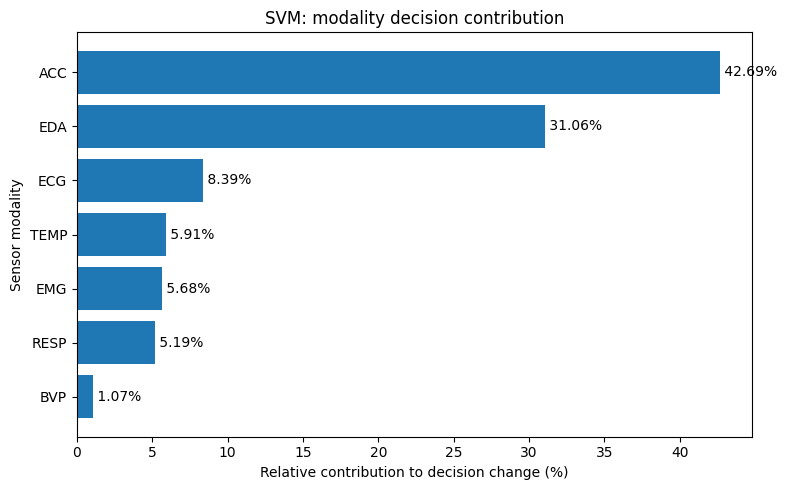

SVM: 4147 identical windows; top modality: ACC (42.69%)


,modality,windows,mean_absolute_decision_change,prediction_change_rate,relative_contribution,rank
0,ACC,4147,0.104277,0.122257,0.426872,1
1,EDA,4147,0.075884,0.080540,0.310641,2
2,ECG,4147,0.020503,0.005064,0.083933,3
3,TEMP,4147,0.014445,0.002653,0.059134,4
4,EMG,4147,0.013863,0.001206,0.056752,5
5,RESP,4147,0.012683,0.001447,0.051918,6
6,BVP,4147,0.002626,0.000965,0.010749,7


,modality,predicted_label,windows,mean_absolute_decision_change,prediction_change_rate,weighted_score_change,weighted_prediction_change
0,ACC,0,3540,0.058595,0.000000,207.427152,0.0
1,ACC,1,607,0.370688,0.835255,225.007884,507.0
2,BVP,0,3540,0.002035,0.000847,7.202632,3.0
3,BVP,1,607,0.006074,0.001647,3.686720,1.0
4,ECG,0,3540,0.014678,0.000000,51.960781,0.0
5,ECG,1,607,0.054475,0.034596,33.066560,21.0
6,EDA,0,3540,0.047091,0.000282,166.700666,1.0
7,EDA,1,607,0.243805,0.548600,147.989422,333.0
8,EMG,0,3540,0.009769,0.000000,34.583752,0.0
9,EMG,1,607,0.037739,0.008237,22.907708,5.0


In [6]:
svm_overall, svm_by_label = analyze_decision_contribution('SVM', MODEL_FILES['SVM'])


### KNN

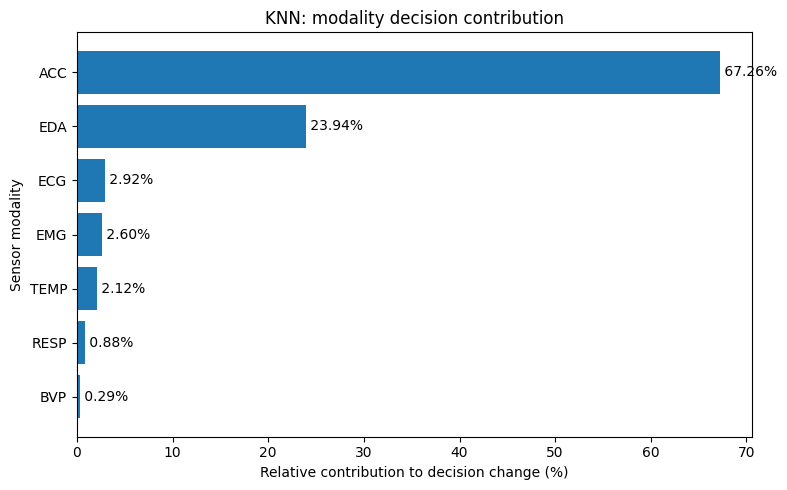

KNN: 4147 identical windows; top modality: ACC (67.26%)


,modality,windows,mean_absolute_decision_change,prediction_change_rate,relative_contribution,rank
0,ACC,4147,0.133349,0.132626,0.672586,1
1,EDA,4147,0.047456,0.045816,0.239358,2
2,ECG,4147,0.005787,0.003617,0.029190,3
3,EMG,4147,0.005160,0.004823,0.026028,4
4,TEMP,4147,0.004196,0.002411,0.021163,5
5,RESP,4147,0.001736,0.000482,0.008757,6
6,BVP,4147,0.000579,0.000482,0.002919,7


,modality,predicted_label,windows,mean_absolute_decision_change,prediction_change_rate,weighted_score_change,weighted_prediction_change
0,ACC,0,3497,0.004404,0.000000,15.4,0.0
1,ACC,1,650,0.827077,0.846154,537.6,550.0
2,BVP,0,3497,0.000515,0.000572,1.8,2.0
3,BVP,1,650,0.000923,0.000000,0.6,0.0
4,ECG,0,3497,0.001773,0.000572,6.2,2.0
5,ECG,1,650,0.027385,0.020000,17.8,13.0
6,EDA,0,3497,0.001887,0.000286,6.6,1.0
7,EDA,1,650,0.292615,0.290769,190.2,189.0
8,EMG,0,3497,0.001201,0.000572,4.2,2.0
9,EMG,1,650,0.026462,0.027692,17.2,18.0


In [7]:
knn_overall, knn_by_label = analyze_decision_contribution('KNN', MODEL_FILES['KNN'])


## ACC-excluded models

These models are retrained using the same complete windows after removing all ACC-derived features. They are separate models because the original standardized models require the original feature count.

In [8]:
NON_ACC_COLUMNS = [column for column in FEATURE_COLUMNS if FEATURE_MODALITIES[column] != 'ACC']
X_NO_ACC = X_ALL[NON_ACC_COLUMNS].copy()
FEATURE_MODALITIES_NO_ACC = FEATURE_MODALITIES[NON_ACC_COLUMNS]
ACC_EXCLUDED_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ACC_EXCLUDED_MODEL_DIR.mkdir(parents=True, exist_ok=True)
print(f'ACC-excluded analysis: {len(X_NO_ACC)} windows, {len(NON_ACC_COLUMNS)} non-ACC features')
print(f'Removed {len(FEATURE_COLUMNS) - len(NON_ACC_COLUMNS)} ACC features')

def scaled_estimator(estimator):
    return Pipeline([('standardize', StandardScaler()), ('normalize', MinMaxScaler()), ('model', estimator)])

def analyze_acc_excluded_model(model_name, model):
    model.fit(X_NO_ACC, Y_ALL)
    original_pred = np.asarray(model.predict(X_NO_ACC)).astype(int)
    original_score = decision_score(model, X_NO_ACC)
    medians = X_NO_ACC.median()
    rows = []
    for modality in sorted(FEATURE_MODALITIES_NO_ACC.unique()):
        columns = FEATURE_MODALITIES_NO_ACC[FEATURE_MODALITIES_NO_ACC == modality].index.tolist()
        masked = X_NO_ACC.copy()
        masked[columns] = medians[columns].to_numpy()
        masked_pred = np.asarray(model.predict(masked)).astype(int)
        score_change = np.abs(original_score - decision_score(model, masked))
        pred_change = (original_pred != masked_pred).astype(int)
        for label in [0, 1]:
            selected = original_pred == label
            rows.append({'modality': modality, 'predicted_label': label, 'windows': int(selected.sum()), 'mean_absolute_decision_change': float(score_change[selected].mean()) if selected.any() else 0.0, 'prediction_change_rate': float(pred_change[selected].mean()) if selected.any() else 0.0})
    detail = pd.DataFrame(rows)
    detail['weighted_score_change'] = detail['mean_absolute_decision_change'] * detail['windows']
    detail['weighted_prediction_change'] = detail['prediction_change_rate'] * detail['windows']
    overall = detail.groupby('modality', as_index=False).agg(windows=('windows', 'sum'), weighted_score_change=('weighted_score_change', 'sum'), weighted_prediction_change=('weighted_prediction_change', 'sum'))
    overall['mean_absolute_decision_change'] = overall['weighted_score_change'] / overall['windows']
    overall['prediction_change_rate'] = overall['weighted_prediction_change'] / overall['windows']
    overall = overall.drop(columns=['weighted_score_change', 'weighted_prediction_change']).sort_values('mean_absolute_decision_change', ascending=False, ignore_index=True)
    total = overall['mean_absolute_decision_change'].sum()
    overall['relative_contribution'] = overall['mean_absolute_decision_change'] / total if total else 0.0
    overall['rank'] = np.arange(1, len(overall) + 1)
    safe_name = model_name.lower().replace(' ', '_')
    joblib.dump(model, ACC_EXCLUDED_MODEL_DIR / f'{safe_name}_acc_excluded.joblib')
    overall.to_csv(ACC_EXCLUDED_OUTPUT_DIR / f'{safe_name}_overall.csv', index=False)
    detail.to_csv(ACC_EXCLUDED_OUTPUT_DIR / f'{safe_name}_by_predicted_label.csv', index=False)

    plot_data = overall.sort_values('mean_absolute_decision_change')
    values = plot_data['relative_contribution'] * 100
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(plot_data['modality'], values)
    ax.set_xlabel('Relative contribution to decision change (%)')
    ax.set_ylabel('Sensor modality')
    ax.set_title(f'{model_name} (ACC excluded)')
    for index, value in enumerate(values):
        ax.text(value, index, f' {value:.2f}%', va='center')
    fig.tight_layout()
    fig.savefig(ACC_EXCLUDED_OUTPUT_DIR / f'{safe_name}_overall.png', dpi=160)
    plt.show()
    plt.close(fig)

    print(f'{model_name} (ACC excluded): {len(X_NO_ACC)} identical windows; top remaining modality: {overall.iloc[0]["modality"]} ({overall.iloc[0]["relative_contribution"]:.2%})')
    display(overall)
    display(detail)
    return overall, detail

ACC_EXCLUDED_MODELS = {
    'Random Forest': scaled_estimator(RandomForestClassifier(n_estimators=100, random_state=100)),
    'XGBoost': scaled_estimator(XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=100)),
    'SVM': scaled_estimator(SVC(kernel='rbf', random_state=100)),
    'KNN': scaled_estimator(KNeighborsClassifier(n_neighbors=5)),
}


ACC-excluded analysis: 4147 windows, 72 non-ACC features
Removed 82 ACC features


### Random Forest without ACC

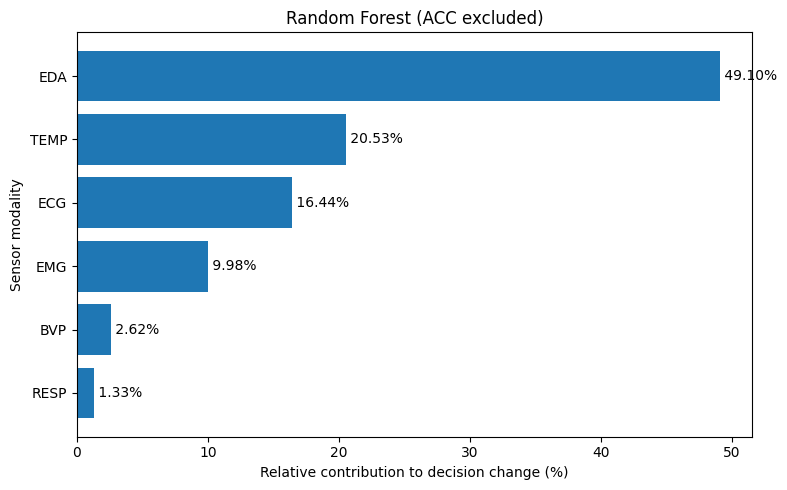

Random Forest (ACC excluded): 4147 identical windows; top remaining modality: EDA (49.10%)


,modality,windows,mean_absolute_decision_change,prediction_change_rate,relative_contribution,rank
0,EDA,4147,0.141068,0.130697,0.491031,1
1,TEMP,4147,0.058985,0.021702,0.205315,2
2,ECG,4147,0.047234,0.031830,0.164413,3
3,EMG,4147,0.028664,0.000723,0.099774,4
4,BVP,4147,0.007528,0.000000,0.026205,5
5,RESP,4147,0.003810,0.000000,0.013262,6


,modality,predicted_label,windows,mean_absolute_decision_change,prediction_change_rate,weighted_score_change,weighted_prediction_change
0,BVP,0,3404,0.006766,0.000000,23.03,0.0
1,BVP,1,743,0.011023,0.000000,8.19,0.0
2,ECG,0,3404,0.017647,0.000000,60.07,0.0
3,ECG,1,743,0.182786,0.177658,135.81,132.0
4,EDA,0,3404,0.042685,0.000000,145.30,0.0
5,EDA,1,743,0.591803,0.729475,439.71,542.0
6,EMG,0,3404,0.015817,0.000000,53.84,0.0
7,EMG,1,743,0.087524,0.004038,65.03,3.0
8,RESP,0,3404,0.002497,0.000000,8.50,0.0
9,RESP,1,743,0.009825,0.000000,7.30,0.0


In [9]:
random_forest_acc_excluded_overall, random_forest_acc_excluded_by_label = analyze_acc_excluded_model('Random Forest', ACC_EXCLUDED_MODELS['Random Forest'])


### XGBoost without ACC

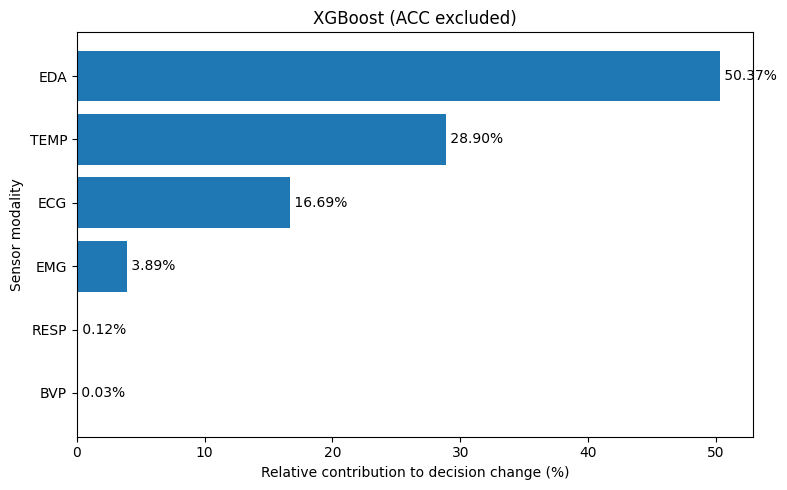

XGBoost (ACC excluded): 4147 identical windows; top remaining modality: EDA (50.37%)


,modality,windows,mean_absolute_decision_change,prediction_change_rate,relative_contribution,rank
0,EDA,4147,0.099616,0.082710,0.503665,1
1,TEMP,4147,0.057165,0.058838,0.289029,2
2,ECG,4147,0.033000,0.034000,0.166851,3
3,EMG,4147,0.007703,0.002894,0.038949,4
4,RESP,4147,0.000243,0.000000,0.001227,5
5,BVP,4147,0.000055,0.000000,0.000279,6


,modality,predicted_label,windows,mean_absolute_decision_change,prediction_change_rate,weighted_score_change,weighted_prediction_change
0,BVP,0,3404,0.000039,0.000000,0.131447,0.0
1,BVP,1,743,0.000131,0.000000,0.097627,0.0
2,ECG,0,3404,0.000769,0.000294,2.618216,1.0
3,ECG,1,743,0.180664,0.188425,134.233321,140.0
4,EDA,0,3404,0.014717,0.011457,50.098328,39.0
5,EDA,1,743,0.488571,0.409152,363.008311,304.0
6,EMG,0,3404,0.006471,0.002056,22.028924,7.0
7,EMG,1,743,0.013347,0.006729,9.916867,5.0
8,RESP,0,3404,0.000212,0.000000,0.722591,0.0
9,RESP,1,743,0.000382,0.000000,0.283553,0.0


In [10]:
xgboost_acc_excluded_overall, xgboost_acc_excluded_by_label = analyze_acc_excluded_model('XGBoost', ACC_EXCLUDED_MODELS['XGBoost'])


### SVM without ACC

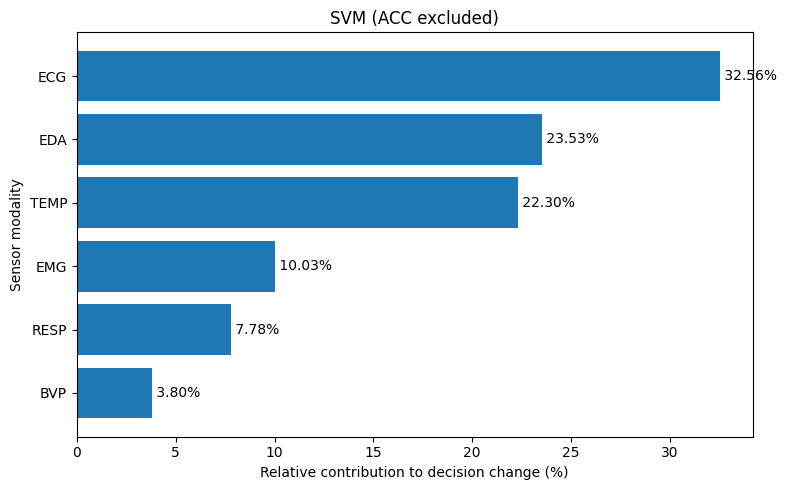

SVM (ACC excluded): 4147 identical windows; top remaining modality: ECG (32.56%)


,modality,windows,mean_absolute_decision_change,prediction_change_rate,relative_contribution,rank
0,ECG,4147,0.101790,0.098626,0.325592,1
1,EDA,4147,0.073568,0.066554,0.235321,2
2,TEMP,4147,0.069731,0.040752,0.223048,3
3,EMG,4147,0.031354,0.027490,0.100292,4
4,RESP,4147,0.024317,0.003617,0.077783,5
5,BVP,4147,0.011869,0.004582,0.037964,6


,modality,predicted_label,windows,mean_absolute_decision_change,prediction_change_rate,weighted_score_change,weighted_prediction_change
0,BVP,0,3526,0.012323,0.005389,43.449397,19.0
1,BVP,1,621,0.009292,0.000000,5.770360,0.0
2,ECG,0,3526,0.092313,0.046795,325.496982,165.0
3,ECG,1,621,0.155595,0.392915,96.624254,244.0
4,EDA,0,3526,0.054295,0.008225,191.444556,29.0
5,EDA,1,621,0.182999,0.397746,113.642448,247.0
6,EMG,0,3526,0.017753,0.003120,62.595805,11.0
7,EMG,1,621,0.108584,0.165862,67.430471,103.0
8,RESP,0,3526,0.023156,0.004254,81.649549,15.0
9,RESP,1,621,0.030908,0.000000,19.193982,0.0


In [11]:
svm_acc_excluded_overall, svm_acc_excluded_by_label = analyze_acc_excluded_model('SVM', ACC_EXCLUDED_MODELS['SVM'])


### KNN without ACC

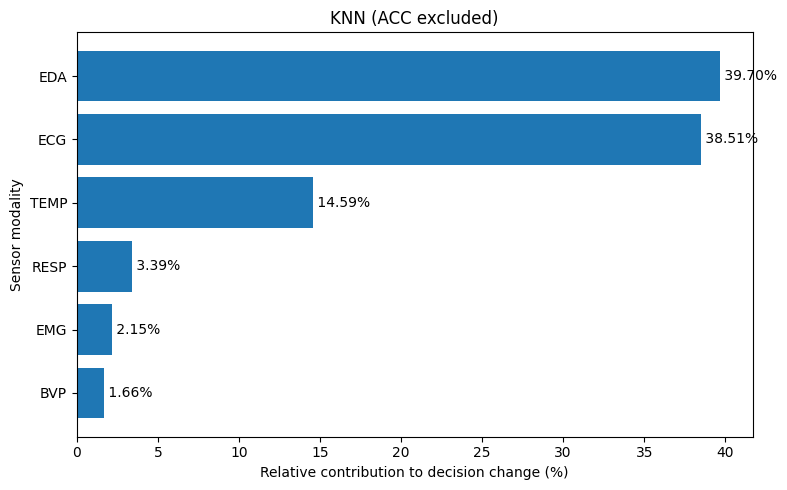

KNN (ACC excluded): 4147 identical windows; top remaining modality: EDA (39.70%)


,modality,windows,mean_absolute_decision_change,prediction_change_rate,relative_contribution,rank
0,EDA,4147,0.077309,0.069448,0.396979,1
1,ECG,4147,0.074994,0.069207,0.385092,2
2,TEMP,4147,0.028406,0.027490,0.145864,3
3,RESP,4147,0.006607,0.004582,0.033928,4
4,EMG,4147,0.004196,0.001929,0.021545,5
5,BVP,4147,0.003231,0.000723,0.016592,6


,modality,predicted_label,windows,mean_absolute_decision_change,prediction_change_rate,weighted_score_change,weighted_prediction_change
0,BVP,0,3407,0.002113,0.000881,7.2,3.0
1,BVP,1,740,0.008378,0.000000,6.2,0.0
2,ECG,0,3407,0.033871,0.024362,115.4,83.0
3,ECG,1,740,0.264324,0.275676,195.6,204.0
4,EDA,0,3407,0.026945,0.015263,91.8,52.0
5,EDA,1,740,0.309189,0.318919,228.8,236.0
6,EMG,0,3407,0.001761,0.000587,6.0,2.0
7,EMG,1,740,0.015405,0.008108,11.4,6.0
8,RESP,0,3407,0.004168,0.004109,14.2,14.0
9,RESP,1,740,0.017838,0.006757,13.2,5.0


In [12]:
knn_acc_excluded_overall, knn_acc_excluded_by_label = analyze_acc_excluded_model('KNN', ACC_EXCLUDED_MODELS['KNN'])
